# Biweeekly Report 3

## Candido Seneriches IV

# Comparative Analysis of AutoAugment, RandAugment, and Mixup

## Introduction
Data augmentation is a widely used technique in deep learning that improves model generalization by introducing variations into training data. Among data augmentation lies three distinct strategies: AutoAugment applies learned transformation policies, RandAugment simplifies augmentation through randomized operations, and Mixup generates new training examples by interpolating images and their labels. So naturally, one might ask, how well do these three methods compare against each other? 

In this experiment, these three methods will be tested against a standard augmentation baseline using a convolutional neural network (CNN) that's trained on the **CIFAR-10 dataset**. Under a controlled training setup, we investigate how each method affects classification accuracy, generalization, and computational efficiency. Our goal is to reproduce key findings from existing augmentation research on a smaller scale and examine how these methods perform under a common experimental framework.

## Mathematical Motivation

Before moving further, let's define what these methods are. While all three methods aim to improve how well a neural network generalizes to unseen data, they approach this problem differently, and each comes with its own advantages and limitations.

To begin, suppose we have a training dataset $\mathcal{D}={(x_i,y_i)}_{i=1}^{n}$, where $x_i$ represents an input image and $y_i$ is its corresponding class label. Normally, a neural network $f\theta$ is trained by minimizing the empirical risk

$$
\hat{R}(\theta)=\frac{1}{n}\sum_{i=1}^{n}\mathcal{L}(f_\theta(x_i),y_i),
$$

where $\theta$ represents the trainable parameters and $\mathcal{L}$ is the loss function. However, minimizing this loss does not necessarily mean that the model will perform equally well on images it has never encountered. This is where data augmentation comes in, as it introduces additional variations into the training process to help reduce overfitting.

### 1. AutoAugment

The first method being investigated is AutoAugment, which attempts to find effective combinations of image transformations through an automated policy-search process. These transformations can include rotations, translations, and adjustments to image properties such as brightness or contrast.

Mathematically, given an augmentation policy $\mathcal{P}$, we can express the training objective as

$$
\hat{R}_{\mathcal{P}}(\theta)
=
\frac{1}{n}\sum_{i=1}^{n}
\mathbb{E}_{T\sim\mathcal{P}}
\left[\mathcal{L}_(f\theta(T(x_i)),y_i)\right],
$$

where $T$ represents a randomly sampled transformation from the policy. Essentially, rather than training on the same original images every time, the CNN encounters different transformed versions of them while retaining their original labels.

The theoretical benefit is that the model can learn to recognize objects despite changes in their appearance or position, potentially improving generalization. However, searching for effective policies can be computationally expensive, and transformations that work well for one dataset may not be equally useful for another. Excessive transformations may also remove important features from an image.

For this experiment, we'll be using the previously discovered CIFAR-10 AutoAugment policy, rather than performing the original policy search. Since the search process is one of AutoAugment's main computational drawbacks, this raises an interesting question: can a simpler method achieve similar results without requiring a learned augmentation policy?

### 2. RandAugment

This brings us to RandAugment, which simplifies the augmentation process by randomly selecting transformations rather than searching for an optimized policy. It is primarily controlled by two hyperparameters:

$N$: the number of augmentation operations applied.

$M$: the magnitude or strength of those operations.

Using the same idea as before, its training objective can be written as

$$
\hat{R}_{N,M}(\theta)
=
\frac{1}{n}\sum_{i=1}^{n}
\mathbb{E}_{T\sim\mathcal{P}_{N,M}}
\left[\mathcal{L}_(f_\theta(T(x_i)),y_i)\right].
$$

Here, $\mathcal{P}_{N,M}$ represents the distribution of transformations determined by the chosen values of $N$ and $M$.

The main advantage of RandAugment is its simplicity. By reducing the number of hyperparameters involved in selecting transformations, it avoids the expensive policy-search procedure used by AutoAugment while still exposing the CNN to a variety of images.

However, randomly chosen transformations are not guaranteed to be useful. If $M$ is too small, the augmented images may be too similar to the originals, while excessively large values may distort important features and make classification more difficult. The choice of $N$ and $M$ can therefore affect how well the method performs.

So far, both AutoAugment and RandAugment have focused on transforming individual images while preserving their class labels. But what if we instead generated new training examples by combining existing images, including their labels? This leads to our final method.

### 3. Mixup

Unlike the previous two methods, Mixup generates synthetic training examples by interpolating between two images and their corresponding labels. Given two observations $(x_i,y_i)$ and $(x_j,y_j)$, the new example is constructed as

$$
\tilde{x}=\lambda x_i+(1-\lambda)x_j,
$$

$$
\tilde{y}=\lambda y_i+(1-\lambda)y_j,
$$

where the interpolation coefficient is sampled from

$$
\lambda\sim\operatorname{Beta}(\alpha,\alpha).
$$

Here, $\alpha>0$ controls how strongly the two examples are mixed. For instance, if $\lambda=0.7$, the resulting image consists of $70%$ of the first image and $30%$ of the second, with the target labels mixed in the same proportions.

Since Mixup produces soft labels rather than a single class label, its cross-entropy loss can be expressed as

$$
\lambda\mathcal{L}(f_\theta(\tilde{x}),y_i)
+
(1-\lambda)\mathcal{L}(f_\theta(\tilde{x}),y_j).
$$

The motivation behind this method is to encourage the network to behave more linearly between training examples, rather than making overly confident predictions based only on individual observations. This can provide regularization and potentially improve generalization.

However, interpolating two images does not necessarily produce a realistic image. Mixing unrelated classes can create ambiguous examples, and excessive interpolation may make it harder for the CNN to learn meaningful distinctions between classes. As a result, the choice of $\alpha$ becomes an important consideration.

#### 4. Experimental Motivation

Now that we've established the mathematics behind these methods, the main question being investigated is how their different approaches to data augmentation affect CNN performance when evaluated under the same training conditions.

To investigate this, we'll train a CNN on CIFAR-10 using four configurations: a standard augmentation baseline, AutoAugment, RandAugment, and Mixup. Each method will be evaluated independently using the same network architecture, data split, and training budget.

we'll focus on comparing classification accuracy, training and validation behavior, and computational cost. Since the original methods were introduced in separate research papers, this experiment will serve as a smaller-scale comparison of their reported benefits rather than an exact reproduction of the original experiments.

With the mathematical motivation established, let's move on to preparing the CIFAR-10 dataset and setting up the experimental framework.


In [26]:
# Numerical computing and reproducibility
import random
import time
import numpy as np

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

# Datasets and image augmentation
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import AutoAugment, AutoAugmentPolicy, RandAugment

# Visualization and evaluation
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

In [27]:
SEED = 42

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Display environment information
print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")

if device.type == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}")
  print(f"Available GPUs: {torch.cuda.device_count()}")

  gpu_memory = torch.cuda.get_device_properties(0).total_memory
  print(f"GPU Memory: {gpu_memory / (1024 ** 3):.2f} GB")

else:
  print("CUDA unavailable. Running on CPU.")

PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Available GPUs: 2
GPU Memory: 14.56 GB


In [28]:
import os
import pickle

# Kaggle CIFAR-10 dataset location
DATA_DIR = "/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py"

def load_cifar_batch(file_path):
  with open(file_path, "rb") as file:
    batch = pickle.load(file, encoding="bytes")

  images = batch[b"data"].reshape(-1, 3, 32, 32)
  images = images.transpose(0, 2, 3, 1)
  labels = np.array(batch[b"labels"])

  return images, labels

# Load the five training batches
train_batches = [
  load_cifar_batch(os.path.join(DATA_DIR, f"data_batch_{i}"))
  for i in range(1, 6)
]

X_train_full = np.concatenate([batch[0] for batch in train_batches])
y_train_full = np.concatenate([batch[1] for batch in train_batches])

# Load the official test batch
X_test, y_test = load_cifar_batch(
  os.path.join(DATA_DIR, "test_batch")
)

# Create a fixed training/validation split
VAL_SIZE = 5000
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X_train_full))

val_indices = indices[:VAL_SIZE]
train_indices = indices[VAL_SIZE:]

X_train = X_train_full[train_indices]
y_train = y_train_full[train_indices]

X_val = X_train_full[val_indices]
y_val = y_train_full[val_indices]

# Display dataset dimensions
print(f"Training: {X_train.shape}, Labels: {y_train.shape}")
print(f"Validation: {X_val.shape}, Labels: {y_val.shape}")
print(f"Testing: {X_test.shape}, Labels: {y_test.shape}")


Training: (45000, 32, 32, 3), Labels: (45000,)
Validation: (5000, 32, 32, 3), Labels: (5000,)
Testing: (10000, 32, 32, 3), Labels: (10000,)


## Preprocessing and data loaders

All four experiments retain the existing split and use CIFAR-10 channel means
`(0.4914, 0.4822, 0.4465)` and standard deviations `(0.2470, 0.2435, 0.2616)`.
Training uses a random 32 × 32 crop with four pixels of padding and a horizontal
flip. AutoAugment or RandAugment runs after these operations, while images are
still PIL images; tensor conversion scales pixels to `[0, 1]` before normalization.
Validation and test images receive only tensor conversion and normalization.

Mixup uses the baseline image pipeline and integer class labels here; image and
label interpolation belongs in the later training loop. Each experiment has its
own loaders and seeded generators, with identical initial training shuffle seeds.
Worker seeds also initialize NumPy and Python randomness. For reproducible independent
runs, reset the global seeds before each experiment (especially with `num_workers=0`)
and rebuild the loaders to reset their generator states. These seeds do not guarantee
deterministic GPU training. Pinned memory is enabled only for CUDA; set `NUM_WORKERS=0`
if multiprocessing is unavailable in the notebook environment.


In [29]:
from torch.utils.data import Dataset

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)


class CIFAR10ArrayDataset(Dataset):
  """Apply an image transform lazily without modifying the source arrays."""

  def __init__(self, images, labels, transform=None):
    if len(images) != len(labels):
      raise ValueError("Images and labels must have the same length.")
    self.images = images
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.images)

  def __getitem__(self, index):
    image = self.images[index]
    if self.transform is not None:
      image = self.transform(image)
    return image, int(self.labels[index])


def build_transforms(num_ops=2, magnitude=9):
  """Build independent training pipelines and a deterministic evaluation pipeline."""
  def training_transform(policy=None):
    operations = [
      transforms.ToPILImage(),
      transforms.RandomCrop(32, padding=4),
      transforms.RandomHorizontalFlip(p=0.5),
    ]
    if policy is not None:
      operations.append(policy)
    operations.extend([
      transforms.ToTensor(),
      transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    return transforms.Compose(operations)

  train_transforms = {
    "baseline": training_transform(),
    "autoaugment": training_transform(
      AutoAugment(policy=AutoAugmentPolicy.CIFAR10)
    ),
    "randaugment": training_transform(
      RandAugment(num_ops=num_ops, magnitude=magnitude)
    ),
    "mixup": training_transform(),
  }
  eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
  ])
  return train_transforms, eval_transform


In [30]:
def seed_worker(worker_id):
  """PyTorch seeds each worker; synchronize its Python and NumPy RNGs."""
  worker_seed = torch.initial_seed() % (2 ** 32)
  np.random.seed(worker_seed)
  random.seed(worker_seed)


def build_data_loaders(
  X_train, y_train, X_val, y_val, X_test, y_test,
  batch_size=128, num_workers=2, num_ops=2, magnitude=9, seed=SEED,
):
  """Return loaders[experiment][split], preserving every supplied sample."""
  train_transforms, eval_transform = build_transforms(num_ops, magnitude)
  val_dataset = CIFAR10ArrayDataset(X_val, y_val, eval_transform)
  test_dataset = CIFAR10ArrayDataset(X_test, y_test, eval_transform)

  def make_loader(dataset, shuffle, loader_seed):
    generator = torch.Generator().manual_seed(loader_seed)
    return DataLoader(
      dataset,
      batch_size=batch_size,
      shuffle=shuffle,
      num_workers=num_workers,
      pin_memory=(device.type == "cuda"),
      drop_last=False,
      worker_init_fn=seed_worker,
      generator=generator,
    )

  loaders = {}
  for name, transform in train_transforms.items():
    train_dataset = CIFAR10ArrayDataset(X_train, y_train, transform)
    loaders[name] = {
      "train": make_loader(train_dataset, True, seed),
      "val": make_loader(val_dataset, False, seed + 1),
      "test": make_loader(test_dataset, False, seed + 2),
    }
  return loaders


BATCH_SIZE = 128
NUM_WORKERS = 2
RAND_NUM_OPS = 2
RAND_MAGNITUDE = 9  # Index in torchvision's default 31 magnitude bins (0–30).

loaders = build_data_loaders(
  X_train, y_train, X_val, y_val, X_test, y_test,
  batch_size=BATCH_SIZE,
  num_workers=NUM_WORKERS,
  num_ops=RAND_NUM_OPS,
  magnitude=RAND_MAGNITUDE,
)
# Example access: loaders["autoaugment"]["train"] or loaders["baseline"]["val"].


In [31]:
# Verification Cell
for name, splits in loaders.items():
  images, labels = next(iter(splits["train"]))

  print(
    f"{name:12s} | "
    f"Images: {tuple(images.shape)} | "
    f"Labels: {tuple(labels.shape)}"
  )


baseline     | Images: (128, 3, 32, 32) | Labels: (128,)
autoaugment  | Images: (128, 3, 32, 32) | Labels: (128,)
randaugment  | Images: (128, 3, 32, 32) | Labels: (128,)
mixup        | Images: (128, 3, 32, 32) | Labels: (128,)


### Visualizing the Augmentation Methods

Before moving on to training the CNN, I want to visualize how each augmentation method modifies the original CIFAR-10 images. Although we've already established the mathematical differences between AutoAugment, RandAugment, and Mixup, examining their outputs will help us better understand how these differences translate into actual training examples.

In particular, I'll compare how AutoAugment and RandAugment transform individual images while preserving their labels, whereas Mixup combines two images and their corresponding labels. This visualization will also help identify whether certain transformations significantly distort the original images before evaluating their effects on model performance.

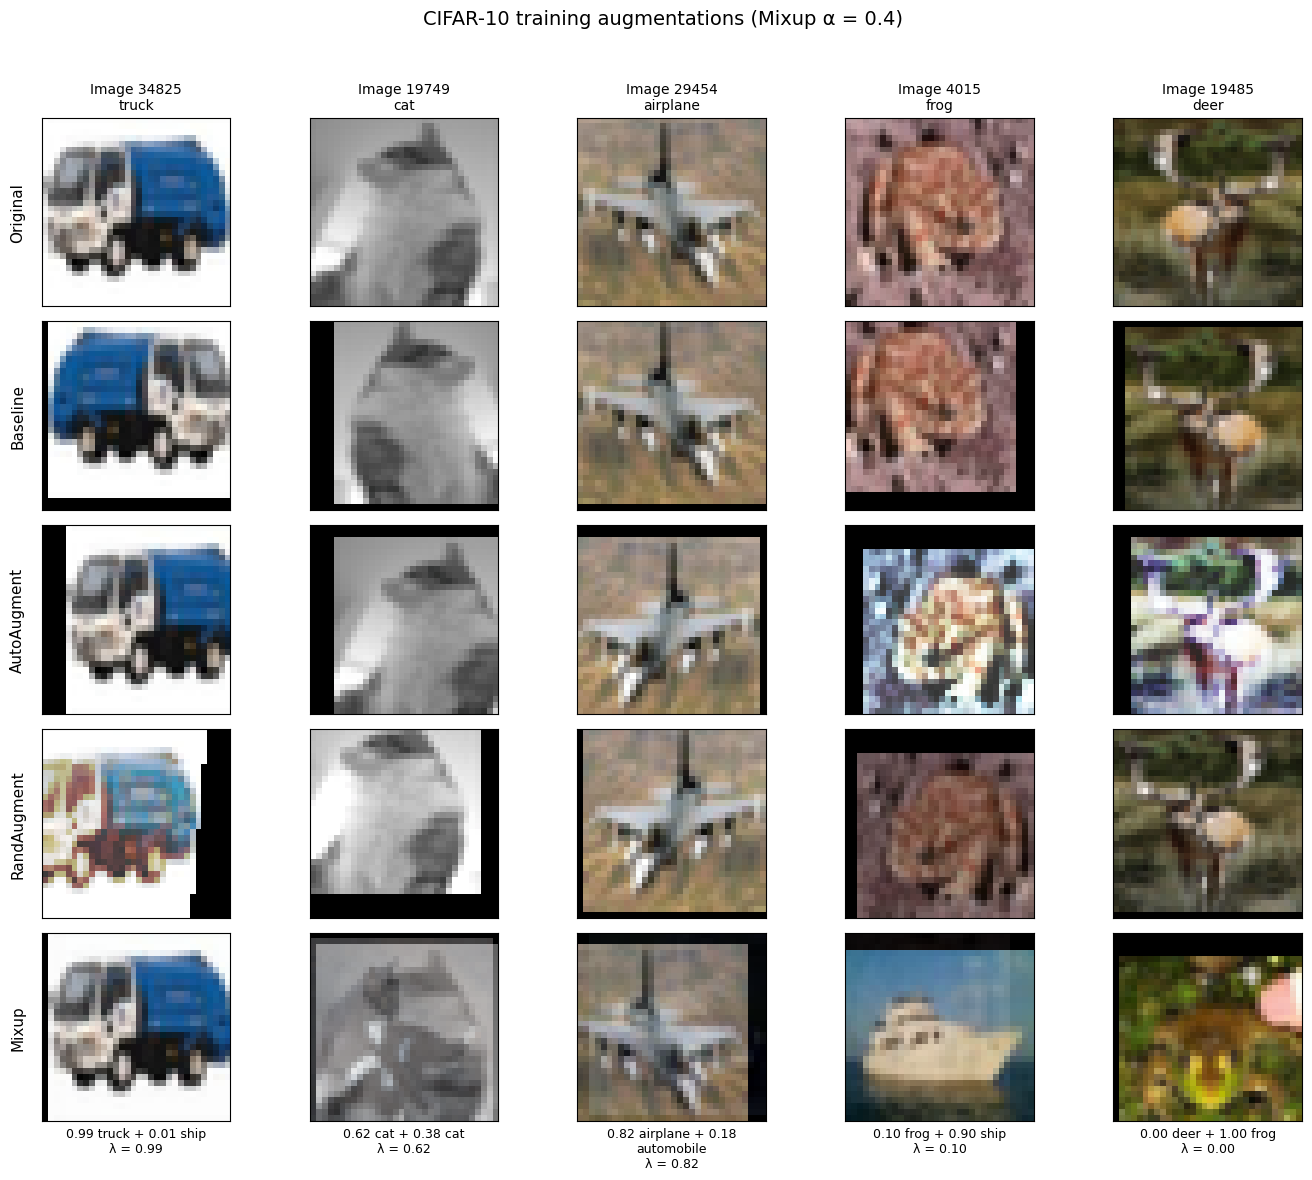

In [32]:
import textwrap

class_names = (
  "airplane", "automobile", "bird", "cat", "deer",
  "dog", "frog", "horse", "ship", "truck",
)
methods = ("baseline", "autoaugment", "randaugment", "mixup")
row_names = ("Original", "Baseline", "AutoAugment", "RandAugment", "Mixup")

alpha = 0.4
rng = np.random.default_rng(SEED)
indices = rng.choice(len(X_train), size=5, replace=False)
# Choose a different training image for each Mixup partner.
partner_indices = (
  indices + rng.integers(1, len(X_train), size=len(indices))
) % len(X_train)
coefficients = rng.beta(alpha, alpha, size=len(indices))

mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(3, 1, 1)


def display_image(tensor):
  image = tensor.detach().cpu()
  return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(5, len(indices), figsize=(14, 12))
python_state = random.getstate()
numpy_state = np.random.get_state()

try:
  # Preserve the CPU RNG used by torchvision's stochastic transforms.
  with torch.random.fork_rng(devices=[]):
    torch.manual_seed(SEED)
    random.seed(SEED)
    np.random.seed(SEED)

    for column, index in enumerate(indices):
      source_class = class_names[int(y_train[index])]
      axes[0, column].imshow(X_train[index])
      axes[0, column].set_title(
        f"Image {int(index)}\n{source_class}", fontsize=10
      )

      for row, method in enumerate(methods, start=1):
        dataset = loaders[method]["train"].dataset
        image, label = dataset[int(index)]

        if method == "mixup":
          partner, partner_label = dataset[int(partner_indices[column])]
          coefficient = float(coefficients[column])
          image = coefficient * image + (1 - coefficient) * partner
          partner_class = class_names[partner_label]

          # The corresponding soft target has these same class weights.
          caption = (
            f"{coefficient:.2f} {class_names[label]} + "
            f"{1 - coefficient:.2f} {partner_class}\n"
            f"λ = {coefficient:.2f}"
          )
          axes[row, column].set_xlabel(
            "\n".join(
              textwrap.fill(line, width=28)
              for line in caption.splitlines()
            ),
            fontsize=9,
          )

        axes[row, column].imshow(display_image(image))

finally:
  random.setstate(python_state)
  np.random.set_state(numpy_state)

for row, row_name in enumerate(row_names):
  axes[row, 0].set_ylabel(row_name, fontsize=11, labelpad=12)
  for axis in axes[row]:
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle(
  f"CIFAR-10 training augmentations (Mixup α = {alpha})",
  fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

From the visualization, we can observe that each augmentation method introduces different types of variation into the CIFAR-10 images. The baseline transformations generally preserve the original appearance of the objects, while AutoAugment and RandAugment can introduce more noticeable changes in color, contrast, and positioning.

Mixup behaves differently by combining two training examples according to a randomly sampled interpolation coefficient. As shown in the figure, the resulting image can closely resemble one of the original examples or contain visible features from both, depending on the value of $\lambda$.

Although these examples help illustrate the differences between the augmentation strategies, they do not establish which method improves classification performance. We will investigate that question through controlled CNN training experiments.